In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = sns.load_dataset('tips')
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [8]:
# مجموع افرادی که غذا خوردند در این رستوران
df['size'].sum()

np.int64(627)

In [9]:
# کمترین و بیشتری افرادی که غذا خوردند
df['size'].min(),df['size'].max()

(np.int64(1), np.int64(6))

In [14]:
# مجموع افرادی که نهار و شام خوردند
df[(df['time'] == "Lunch")]['size'].sum(), df[(df['time'] == "Dinner")]['size'].sum()


(np.int64(164), np.int64(463))

(array([176.,  68.]),
 array([0. , 0.5, 1. ]),
 <BarContainer object of 2 artists>)

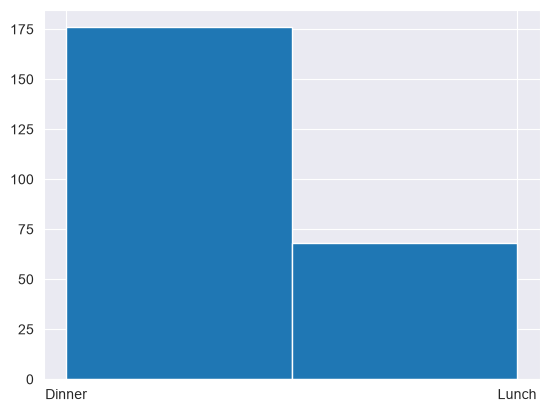

In [25]:
plt.hist(df['time'], bins=2)

In [32]:
# مجموع آقایان و خانم های سیگاری
# df['smoker_id'] = df['smoker'].map({'Yes': 1, 'No': 0})
df[df['sex'] == 'Female']['smoker'].value_counts()

smoker
No     54
Yes    33
Name: count, dtype: int64

(array([54., 33.]), array([0. , 0.5, 1. ]), <BarContainer object of 2 artists>)

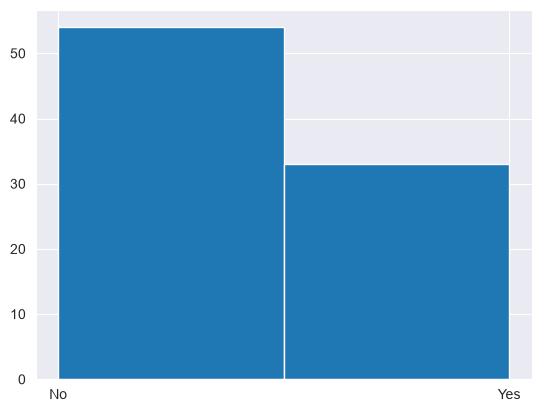

In [34]:
plt.hist((df[df['sex'] == 'Female']['smoker']), bins=2)

In [35]:
df[df['sex'] == 'Male']['smoker'].value_counts()

smoker
No     97
Yes    60
Name: count, dtype: int64

(array([97., 60.]), array([0. , 0.5, 1. ]), <BarContainer object of 2 artists>)

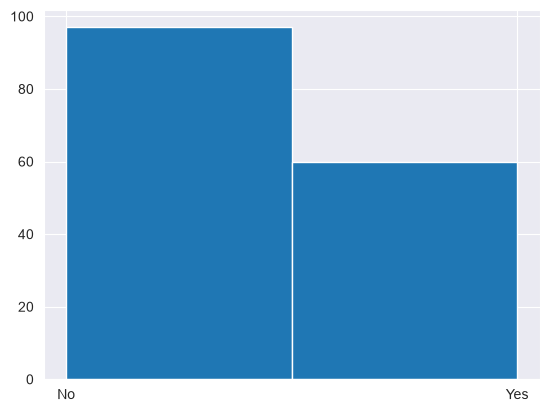

In [37]:
plt.hist((df[df['sex'] == 'Male']['smoker']), bins=2)

In [47]:
# مجموه مهمان های سیگاری
df[(df['smoker_id'] == 1)]['size'].sum()

np.int64(627)

In [48]:
df['smoker'].value_counts()

smoker
No     151
Yes     93
Name: count, dtype: int64

(array([151.,  93.]),
 array([0. , 0.5, 1. ]),
 <BarContainer object of 2 artists>)

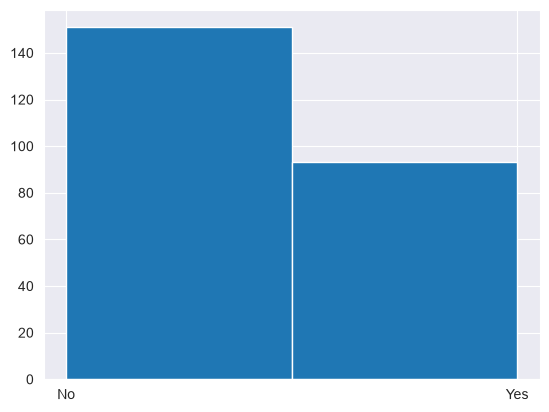

In [51]:
plt.hist((df['smoker']), bins=2)

In [53]:
# خانم های سیگاری که نهار خوردند
df[(df['sex'] == 'Female') & (df['smoker_id'] == 1) & (df['time'] == "Lunch")]['size'].sum()

np.int64(23)

(array([23., 10.]), array([0. , 0.5, 1. ]), <BarContainer object of 2 artists>)

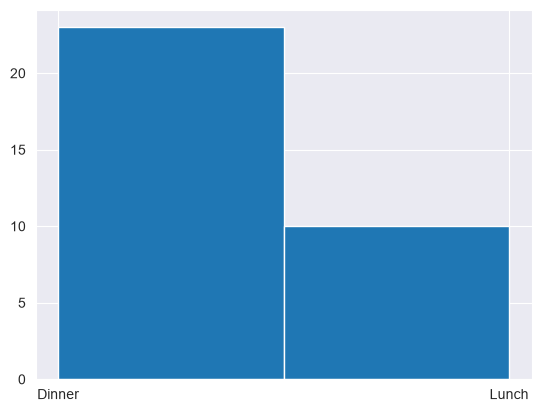

In [56]:
plt.hist((df[(df['sex'] == 'Female') & (df['smoker_id'] == 1)]['time']), bins=2)

In [58]:
# مجموع پرداختی ها
df['total_bill'].sum()

np.float64(4827.77)

In [59]:
# میانگین مبالغ پرد اختی
df['total_bill'].mean()

np.float64(19.78594262295082)

In [60]:
# کمترین و بیشترین مبلغ پرداختی
df['total_bill'].min(), df['total_bill'].max()

(np.float64(3.07), np.float64(50.81))

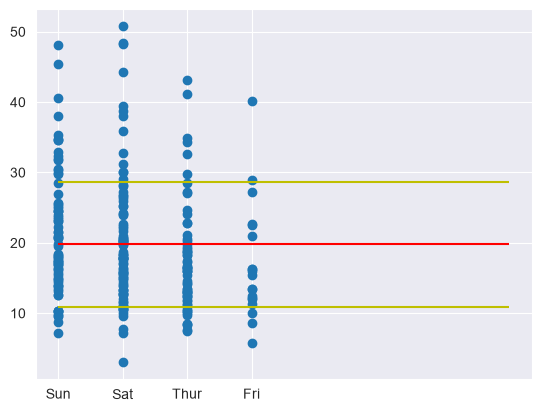

In [66]:
plt.scatter(df['day'], df['total_bill'])

mean_bill = df['total_bill'].mean()
std_bill = df['total_bill'].std()

upper_bill = mean_bill + std_bill
lower_bill = mean_bill - std_bill

plt.hlines(mean_bill,0, 7,  color='r')
plt.hlines(upper_bill,0, 7, color='y')
plt.hlines(lower_bill,0, 7,  color='y')

plt.show()

In [68]:
outlier = df[(df['total_bill'] > upper_bill) | (df['total_bill'] < lower_bill)]
outlier

,total_bill,tip,sex,smoker,day,time,size,smoker_id
1,10.34,1.66,Male,No,Sun,Dinner,3,0
6,8.77,2.00,Male,No,Sun,Dinner,2,0
10,10.27,1.71,Male,No,Sun,Dinner,2,0
11,35.26,5.00,Female,No,Sun,Dinner,4,0
16,10.33,1.67,Female,No,Sun,Dinner,3,0
...,...,...,...,...,...,...,...,...
233,10.77,1.47,Male,No,Sat,Dinner,2,0
235,10.07,1.25,Male,No,Sat,Dinner,2,0
237,32.83,1.17,Male,Yes,Sat,Dinner,2,1
238,35.83,4.67,Female,No,Sat,Dinner,3,0


In [73]:
# میانگین مبلغ فروش روز یکشنبه
df[df['day'] == "Sun"]['total_bill'].mean()

np.float64(21.41)